# 05 · Explainability and risk scoring
SHAP values decompose each prediction (in log-odds) into additive feature contributions. They describe
how the **model** uses features, not what **causes** fraud. Figures come from `python -m src.explainability`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
from src import config

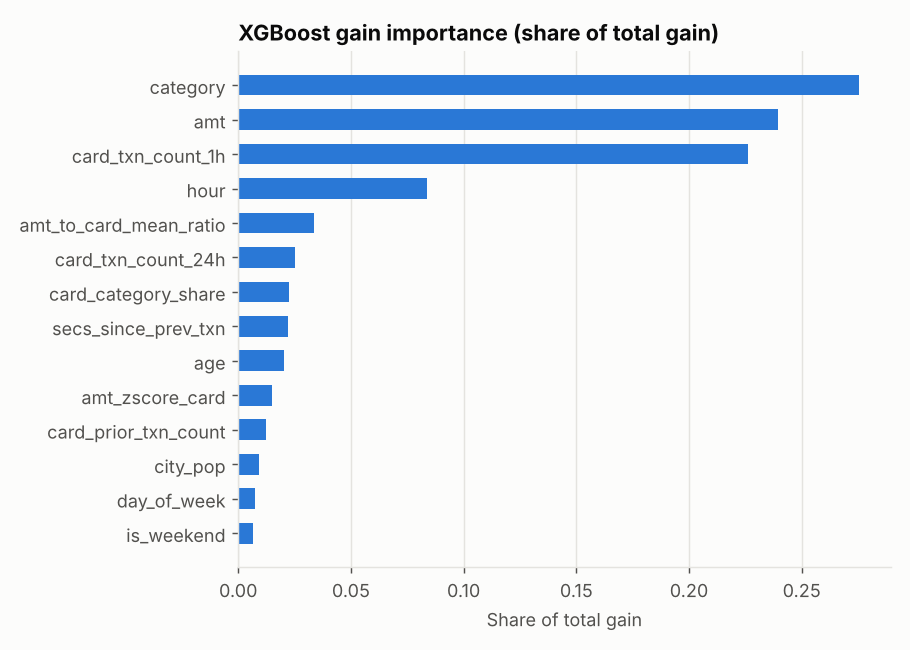

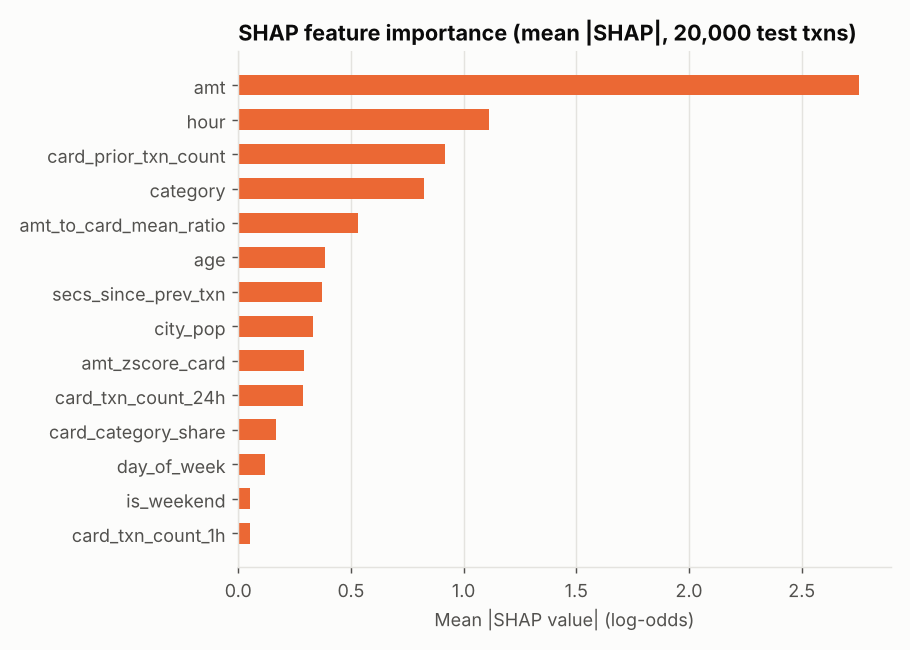

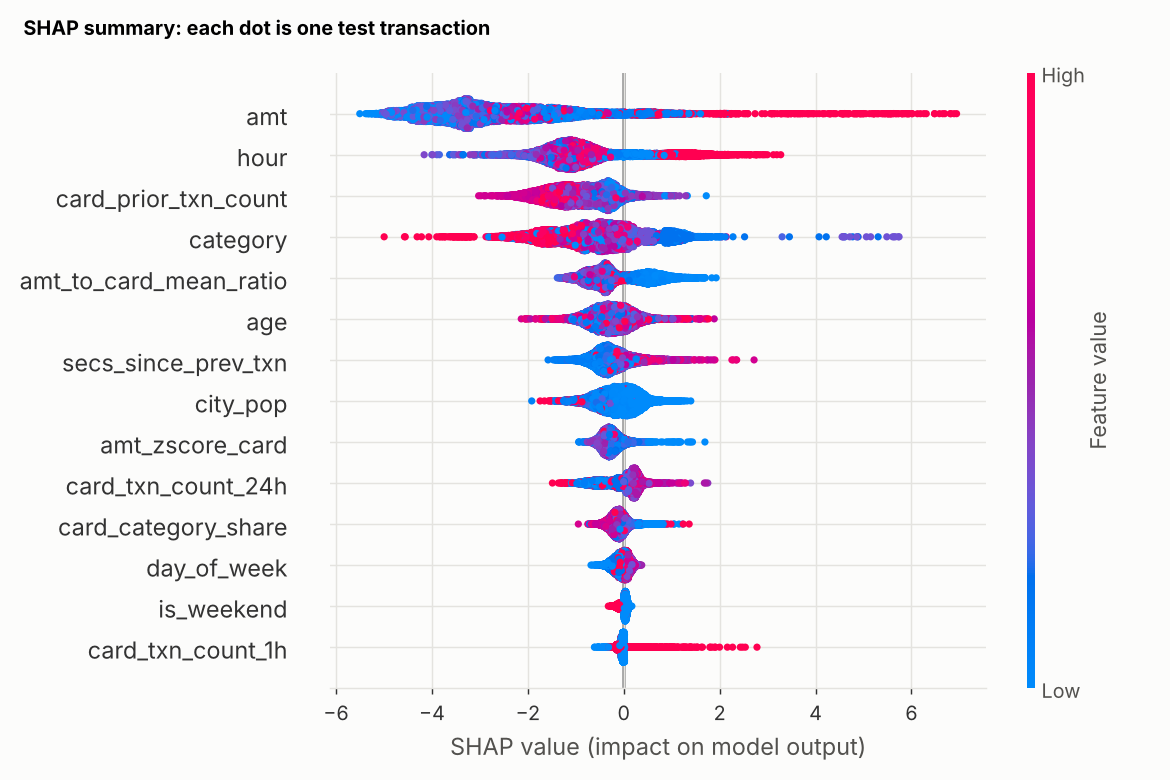

In [2]:
for f in ['xgb_gain_importance.png', 'shap_importance.png', 'shap_summary.png']:
    display(Image(filename=str(config.SHAP_FIGURES_DIR / f)))

## Individual explanations: a caught fraud and a false alert

### true_positive

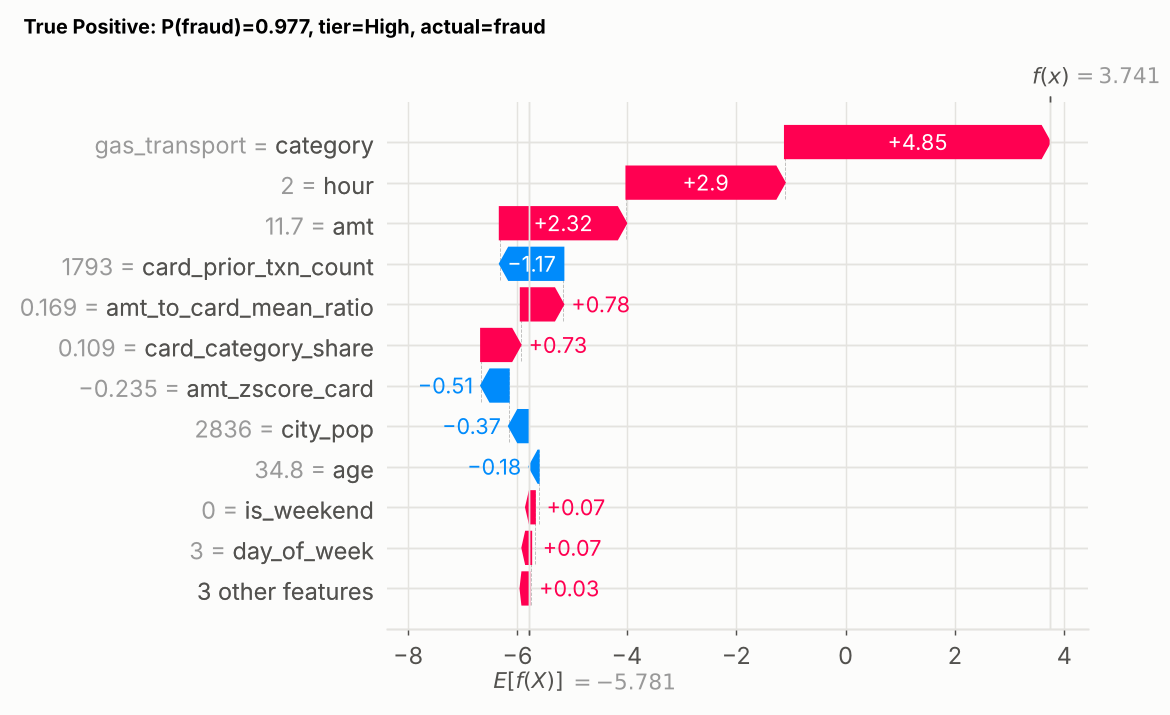

,feature,value,shap_log_odds,direction
0,category,gas_transport,4.850975,raises risk
1,hour,2,2.898574,raises risk
2,amt,11.7,2.316041,raises risk
3,card_prior_txn_count,1793,-1.166366,lowers risk
4,amt_to_card_mean_ratio,0.1692932496474419,0.782497,raises risk
5,card_category_share,0.10875627440044618,0.725578,raises risk
6,amt_zscore_card,-0.23454983834688167,-0.507851,lowers risk
7,city_pop,2836,-0.371611,lowers risk


### false_positive

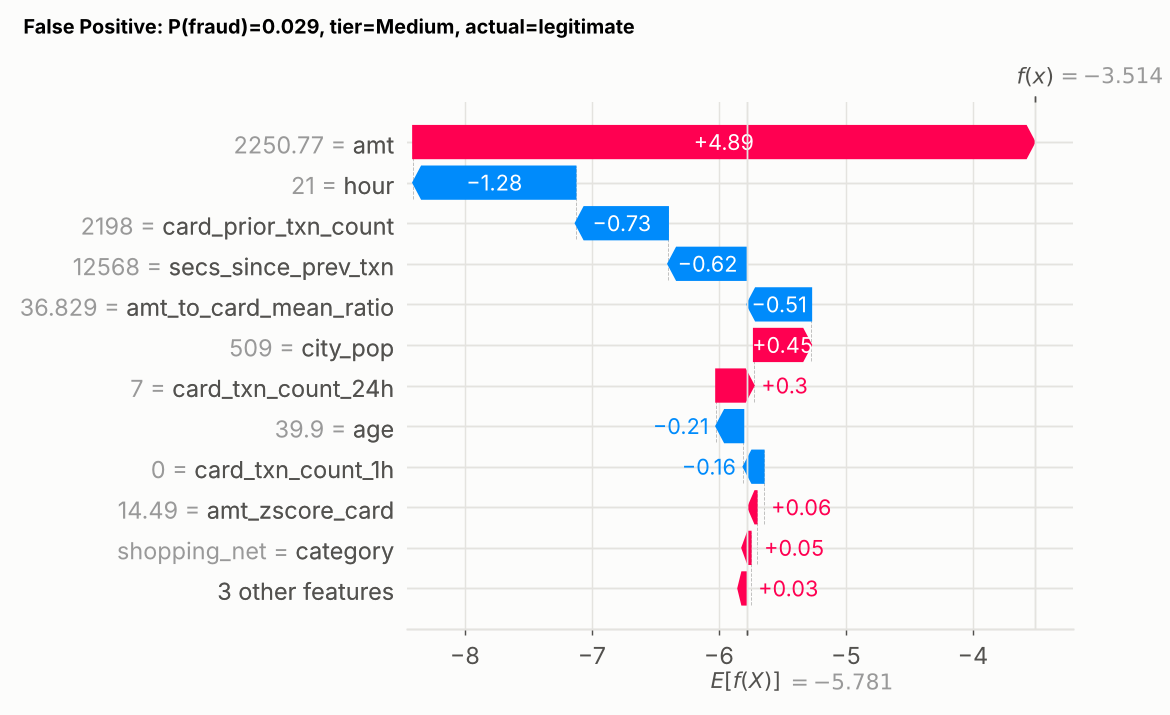

,feature,value,shap_log_odds,direction
0,amt,2250.77,4.894201,raises risk
1,hour,21,-1.279537,lowers risk
2,card_prior_txn_count,2198,-0.728230,lowers risk
3,secs_since_prev_txn,12568.0,-0.622137,lowers risk
4,amt_to_card_mean_ratio,36.82876992971614,-0.505312,lowers risk
5,city_pop,509,0.452129,raises risk
6,card_txn_count_24h,7,0.297111,raises risk
7,age,39.9,-0.214899,lowers risk


In [3]:
for label in ['true_positive', 'false_positive']:
    display(Markdown(f'### {label}'))
    display(Image(filename=str(config.SHAP_FIGURES_DIR / f'waterfall_{label}.png')))
    display(pd.read_csv(config.REPORTS_DIR / f'shap_example_{label}.csv').head(8))

## Risk tiers on the test period

In [4]:
from src.risk import load_thresholds
print(load_thresholds())
pd.read_csv(config.REPORTS_DIR / 'risk_tier_summary.csv').round(3)

RiskThresholds(medium=0.012193311005830765, high=0.19233089685440063)


,tier,n_transactions,n_fraud,fraud_rate_pct,share_of_transactions_pct,share_of_all_fraud_pct
0,Low,552063,151,0.027,99.342,7.040
1,Medium,1784,250,14.013,0.321,11.655
2,High,1872,1744,93.162,0.337,81.305
